# CLK19 affinity-maturation pipeline

**Part 1** — derivation of the CLK19 germline (`CLK19gl`) nucleotide sequence from the designed
`CLK19min` nucleotide sequence and the protein in `CLK19gl_eOD-GT8_modeller.pdb`.

**Part 2** — consensus analysis of BCR nucleotide sequences recovered from mice that received
B cells carrying either the CLK19 germline or the CLK19min nucleotide sequence, at day 8 and
day 21 post-immunisation.

The two parts meet in Part 3: the consensus of the CLK19 group *is* the true starting germline
sequence, which resolves the junction nucleotides that Part 1 could only infer. Part 3 then exports
the final sequences in the reading frame the collaborators supplied — heavy 360 nt, light 300 nt —
which maps 1:1 onto the protein in `CLK19gl_eOD-GT8_modeller.pdb` (see 3.2).

Requirements: `biopython`, `pandas`, `numpy`, `matplotlib`, `openpyxl`.
Place `Sequence data from single transferred group.xlsx` next to this notebook.


In [1]:
import re, urllib.request
from collections import Counter
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from Bio.Seq import Seq

XLSX = "Sequence data from single transferred group.xlsx"
pd.set_option("display.width", 200)

---
# Part 1 — deriving CLK19gl from CLK19min

## 1.1 Inputs

`CLK19min` was supplied by the collaborators as two nucleotide sequences, together with `CLK19max`,
a second synonymous recoding of the same protein pair. The heavy chain is a complete 360 nt V(D)J.
The light chain is 300 nt and stops nine nucleotides before the end of IGKJ3*01; those nine
nucleotides (`GATATCAAA`, Asp-Ile-Lys) are restored in 1.4 so that the germline gene assignment and
the repertoire comparison in Part 2 run against a complete kappa domain.

They are then dropped again before export (3.2). The protein in `CLK19gl_eOD-GT8_modeller.pdb` was
homology-modelled from the 300 nt light chain as supplied, so the sequences used for the
affinity-maturation simulations are kept in that same frame and correspond 1:1 to the model.


In [2]:
CLK19min_HC = (
 "CAGGTCCAGTTGGTCCAGTCGGGGGCCGAGGTCAAGAAGCCTGGGGCCTCGGTCAAAGTCTCCTGTAAGGCCTCGGGCTACACTTTCACG"
 "GGCTATTACATGCACTGGGTCCGCCAGGCCCCGGGCCAGGGCCTCGAGTGGATGGGGTGGATCAATCCCAATTCCGGGGGGACAAACTAT"
 "GCCCAGAAGTTTCAGGGCCGGGTCACCATGACGAGGGACACATCCATCTCGACGGCCTACATGGAGTTGTCGAGACTCCGGTCCGACGAC"
 "ACGGCCGTCTATTATTGCGCCACAGCCCTCGCAGGATATAGGTGGCGCTTTGACTATTGGGGCCAGGGAACTCTCGTCACGGTCTCGTCC")

CLK19max_HC = (
 "CAAGTACAGCTAGTACAAAGCGGTGCGGAAGTAAAAAAACCTGGTGCAAGCGTAAAGGTAAGCTGCAAAGCAAGCGGGTATACGTTTACT"
 "GGGTACTATATGCATTGGGTACGGCAAGCACCTGGGCAAGGTCTAGAATGGATGGGATGGATTAACCCAAATAGCGGTGGTACTAACTAC"
 "GCACAAAAATTCCAAGGTAGAGTAACGATGACAAGGGATACTAGCATTAGCACTGCGTATATGGAGCTTAGCAGGTTACGTAGCGATGAT"
 "ACTGCGGTATACTACTGCGCAACGGCCTTAGCAGGGTATCGCTGGAGGTTTGATTACTGGGGGCAAGGTACGCTAGTAACTGTAAGCAGC")

CLK19min_LC_as_supplied = (
 "GACATCCAGATGACCCAGTCTCCATCCTCCCTGTCTGCATCTGTAGGAGACAGAGTCACCATCACTTGCCAGGCGAGTCAGGACATTAGC"
 "AACTATTTAAATTGGTATCAGCAGAAACCAGGGAAAGCCCCTAAGCTCCTGATCTACGATGCATCCAATTTGGAAACAGGGGTCCCATCA"
 "AGGTTCAGTGGAAGTGGATCTGGGACAGATTTTACTTTCACCATCAGCAGCCTGCAGCCTGAAGATATTGCAACATATTACTGTCAACAG"
 "TATGCAACCTTCGGCCCTGGGACCAAAGTG")

CLK19max_LC = (
 "GATATACAAATGACGCAAAGCCCTAGCAGCTTAAGCGCAAGCGTAGGTGATAGGGTAACGATTACTTGCCAAGCAAGCCAAGATATTAGC"
 "AACTACCTAAATTGGTACCAACAAAAACCTGGTAAAGCACCTAAACTACTAATATATGATGCAAGCAACCTAGAAACGGGAGTACCTAGC"
 "AGGTTTAGCGGTAGCGGTAGCGGTACGGATTTTACGTTTACTATTAGCAGCTTACAACCAGAGGATATAGCAACGTACTACTGCCAGCAG"
 "TACGCCACGTTCGGACCTGGTACTAAAGTA")

# protein of the Fv in CLK19gl_eOD-GT8_modeller.pdb (chain B 178-297, chain C 401-500)
PDB_HC_aa = ("QVQLVQSGAEVKKPGASVKVSCKASGYTFTGYYMHWVRQAPGQGLEWMGWINPNSGGTNYAQKFQGRVTMTRDTSISTAYMELSRLRSDD"
             "TAVYYCATALAGYRWRFDYWGQGTLVTVSS")
PDB_LC_aa = ("DIQMTQSPSSLSASVGDRVTITCQASQDISNYLNWYQQKPGKAPKLLIYDASNLETGVPSRFSGSGSGTDFTFTISSLQPEDIATYYCQQ"
             "YAT")

print(len(CLK19min_HC), "nt ->", str(Seq(CLK19min_HC).translate()) == PDB_HC_aa)
print(len(CLK19min_LC_as_supplied), "nt ->", str(Seq(CLK19min_LC_as_supplied).translate()) == PDB_LC_aa + "FGPGTKV")
print("CLK19max encodes the same protein pair:",
      str(Seq(CLK19max_HC).translate()) == PDB_HC_aa,
      str(Seq(CLK19max_LC).translate()) == PDB_LC_aa + "FGPGTKV")


360 nt -> True
300 nt -> True
CLK19max encodes the same protein pair: True True


## 1.2 Germline gene assignment

V domains were numbered under the IMGT scheme with ANARCI and compared against every human allele in
its reference set (run separately; results quoted here):

| chain | gene | evidence |
|---|---|---|
| heavy | **IGHV1-2\*02** + **IGHJ4** | single mismatch at IMGT 106, which lies in CDR-H3 and is therefore junctional |
| light | **IGKV1-33\*01** (= IGKV1D-33\*01) + **IGKJ3\*01** | zero mismatches across the V region |

IGHV1-2\*02 and \*04 differ at exactly one nucleotide — position 199, AGG (Arg) vs TGG (Trp) at
IMGT 75. CLK19min carries CGG there, one nucleotide from each allele, so nucleotide evidence cannot
discriminate them. The protein does: both the translation and the deposited structure carry **Arg**,
which excludes \*04.

All assignments were confirmed independently by IgBLAST (human IMGT databases, blastn, V mismatch
penalty −1, IMGT domain classification): IGHV1-2\*02 at 81.4% nucleotide identity with IGHJ4\*02,
and IGKV1-33\*01/IGKV1D-33\*01 at 100.0% with IGKJ3\*01; both productive and in frame.

## 1.3 Germline nucleotide segments from GenBank

Reading frames are established by six-frame translation and matching the known germline peptide, so
no coordinate or frame is assumed. Cached literals let the notebook run offline.

In [3]:
CACHE = {
 "IGHV1-2*02_V": ("CAGGTGCAGCTGGTGCAGTCTGGGGCTGAGGTGAAGAAGCCTGGGGCCTCAGTGAAGGTCTCCTGCAAGGCTTCTGGATACACCTTCACC"
                  "GGCTACTATATGCACTGGGTGCGACAGGCCCCTGGACAAGGGCTTGAGTGGATGGGATGGATCAACCCTAACAGTGGTGGCACAAACTAT"
                  "GCACAGAAGTTTCAGGGCAGGGTCACCATGACCAGGGACACGTCCATCAGCACAGCCTACATGGAGCTGAGCAGGCTGAGATCTGACGAC"
                  "ACGGCCGTGTATTACTGTGCG"),
 "IGHJ4*02":     "TACTTTGACTACTGGGGCCAGGGAACCCTGGTCACCGTCTCCTCA",
 "IGKV1-33*01_V":("GACATCCAGATGACCCAGTCTCCATCCTCCCTGTCTGCATCTGTAGGAGACAGAGTCACCATCACTTGCCAGGCGAGTCAGGACATTAGC"
                  "AACTATTTAAATTGGTATCAGCAGAAACCAGGGAAAGCCCCTAAGCTCCTGATCTACGATGCATCCAATTTGGAAACAGGGGTCCCATCA"
                  "AGGTTCAGTGGAAGTGGATCTGGGACAGATTTTACTTTCACCATCAGCAGCCTGCAGCCTGAAGATATTGCAACATATTACTGTCAACAG"
                  "TAT"),
 "IGKJ3*01":     "TTCACTTTCGGCCCTGGGACCAAAGTGGATATCAAA",
}

def efetch(acc):
    url = ("https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
           f"?db=nuccore&id={acc}&rettype=fasta&retmode=text")
    return "".join(urllib.request.urlopen(url, timeout=60).read().decode().split("\n")[1:]).upper()

def find_peptide(nt, motif):
    """Return (nt_start, protein) for the first six-frame translation containing `motif`."""
    for strand, s in [("+", nt), ("-", str(Seq(nt).reverse_complement()))]:
        for f in range(3):
            p = str(Seq(s[f:len(s) - ((len(s) - f) % 3)]).translate())
            i = p.find(motif)
            if i >= 0:
                return s, f + 3 * i, p[i:]
    raise ValueError("motif not found")

try:
    X62106 = efetch("X62106")                 # IGHV1-2*02
    M64856 = efetch("M64856")                 # IGKV1-33*01
    X86355 = efetch("X86355")                 # IGHJ locus, contains IGHJ4*02
    s, i, p = find_peptide(X62106, "QVQLVQSGAEVKKPGASVKVSC"); IGHV = s[i:i + 3 * p.index("*")]
    s, i, p = find_peptide(M64856, "DIQMTQSPSSLSASVGDRVTITC"); IGKV = s[i:i + 3 * p.index("*")]
    s, i, p = find_peptide(X86355, "YFDYWGQGTLVTVSS");        IGHJ4 = s[i:i + 45]
    IGHV1_2_V, IGKV1_33_V, IGHJ4_02 = IGHV[:291], IGKV[:273], IGHJ4
    IGKJ3_01 = CACHE["IGKJ3*01"]              # J00242 nt 919-954, annotated J_segment feature
    print("fetched from GenBank")
except Exception as e:
    print("offline, using cached literals:", type(e).__name__)
    IGHV1_2_V, IGHJ4_02 = CACHE["IGHV1-2*02_V"], CACHE["IGHJ4*02"]
    IGKV1_33_V, IGKJ3_01 = CACHE["IGKV1-33*01_V"], CACHE["IGKJ3*01"]

assert IGHV1_2_V == CACHE["IGHV1-2*02_V"] and IGKV1_33_V == CACHE["IGKV1-33*01_V"]
assert IGHJ4_02 == CACHE["IGHJ4*02"]
for n, s in [("IGHV1-2*02 V", IGHV1_2_V), ("IGHJ4*02", IGHJ4_02),
             ("IGKV1-33*01 V", IGKV1_33_V), ("IGKJ3*01", IGKJ3_01)]:
    print(f"{n:16s} {len(s):3d} nt  {Seq(s).translate()}")

fetched from GenBank
IGHV1-2*02 V     291 nt  QVQLVQSGAEVKKPGASVKVSCKASGYTFTGYYMHWVRQAPGQGLEWMGWINPNSGGTNYAQKFQGRVTMTRDTSISTAYMELSRLRSDDTAVYYCA
IGHJ4*02          45 nt  YFDYWGQGTLVTVSS
IGKV1-33*01 V    273 nt  DIQMTQSPSSLSASVGDRVTITCQASQDISNYLNWYQQKPGKAPKLLIYDASNLETGVPSRFSGSGSGTDFTFTISSLQPEDIATYYCQQY
IGKJ3*01          36 nt  FTFGPGTKVDIK


## 1.4 Segment boundaries and assembly

The germline **V** contribution is truncated at the last codon where the germline V protein and the
CLK19 protein agree — 97 codons (291 nt, IMGT 1–105, …AVYYC**A**) for the heavy chain and 91 codons
(273 nt, IMGT 1–107, …ATYYCQQ**Y**) for the light chain.

The germline **J** contribution starts at the first codon the J actually templates in this
rearrangement. In both chains the J's own first codon is replaced by a junctional residue
(heavy Tyr→Arg, light Phe→Ala), so it is excluded: IGHJ4\*02 from Phe of FDY (42 nt) and
IGKJ3\*01 from Thr (33 nt).

Everything between is **junction** — D-gene, exonuclease trimming, N/P addition. Its nucleotides
cannot be recovered from protein (degenerate codons; a D gene cannot be called from nine residues of
recoded CDR-H3), so they are carried over from CLK19min and flagged. Part 3 replaces them with the
experimentally observed nucleotides.

The nine light-chain nucleotides restored above serve the germline derivation and the repertoire
comparison in Part 2 only. Section 3.2 trims them off again for the sequences that go into the
affinity-maturation simulations.


In [4]:
H_V, H_J = IGHV1_2_V, IGHJ4_02[3:]            # 291 nt, 42 nt
L_V, L_J = IGKV1_33_V, IGKJ3_01[3:]           # 273 nt, 33 nt
H_junction_inferred = CLK19min_HC[291:318]    # 27 nt, encodes TALAGYRWR  <- NOT germline-determined
L_junction_inferred = CLK19min_LC_as_supplied[273:276]  # 3 nt, encodes Ala  <- partly inferred

CLK19min_LC = CLK19min_LC_as_supplied + "GATATCAAA"     # IGKJ3*01 D-I-K (IMGT 125-127);
                                                        # derivation frame only -- trimmed at 3.2
CLK19gl_HC_inferred = H_V + H_junction_inferred + H_J
CLK19gl_LC_inferred = L_V + L_junction_inferred + L_J

assert str(Seq(CLK19gl_HC_inferred).translate()) == str(Seq(CLK19min_HC).translate()) == PDB_HC_aa
assert str(Seq(CLK19gl_LC_inferred).translate()) == str(Seq(CLK19min_LC).translate()) == PDB_LC_aa + "FGPGTKVDIK"

ham = lambda a, b: sum(x != y for x, y in zip(a, b))
print("HC:", len(CLK19gl_HC_inferred), "nt | min vs gl nt differences:", ham(CLK19min_HC, CLK19gl_HC_inferred))
print("LC:", len(CLK19gl_LC_inferred), "nt | min vs gl nt differences:", ham(CLK19min_LC, CLK19gl_LC_inferred))
print("amino-acid differences: 0 and 0")


HC: 360 nt | min vs gl nt differences: 60
LC: 309 nt | min vs gl nt differences: 1
amino-acid differences: 0 and 0


---
# Part 2 — consensus of the recovered BCR repertoires

## 2.1 Load and QC

Eight sheets: {CLK19 germline, CLK19min} x {heavy, light} x {day 8, day 21}. Sequence IDs encode the
mouse (`CLK19-1..5`, `CLK19min-1..5` at D21; `M1, M2, …` at D8) and a cell barcode.

In [5]:
xl = pd.ExcelFile(XLSX)
recs = []
for s in xl.sheet_names:
    if s.strip() == "instruction":
        continue
    d = xl.parse(s)
    name = s.strip()
    grp = "CLK19min" if "min" in name.lower() else "CLK19gl"
    chain = "HC" if "-HC" in name else "LC"
    day = "D21" if "D21" in name else "D8"
    col = [c for c in d.columns if "REGION" in c][0]
    for sid, seq in zip(d["Sequence ID"], d[col]):
        if isinstance(seq, str):
            recs.append(dict(group=grp, chain=chain, day=day, sid=sid,
                             mouse=str(sid).split("_")[0], seq=seq.strip().upper(),
                             L=len(seq.strip())))
rep = pd.DataFrame(recs)
rep.groupby(["group", "chain", "day"]).agg(n=("seq", "size"), n_mice=("mouse", "nunique"),
                                           min_len=("L", "min"), median_len=("L", "median"),
                                           max_len=("L", "max"))

n  n_mice  min_len  median_len  max_len
group    chain day                                            
CLK19gl  HC    D21   228       4      361       361.0      364
               D8   1723       5      361       361.0      361
         LC    D21   228       4      310       310.0      310
               D8   1722       5      310       310.0      310
CLK19min HC    D21   575       5      355       361.0      361
               D8   1166       5      358       361.0      361
         LC    D21   568       5      310       310.0      310
               D8   1137       5      310       310.0      310

Reads are a fixed length apart from a handful of indel-containing sequences. The IMGT
`V-(D)-J-REGION` carries one nucleotide past the end of our reference sequences (the IGHJ splice-donor
`g` in the heavy chain; one nucleotide of IGKJ/IGKC in the light chain), hence 361 and 310 nt.

Non-modal-length sequences are excluded so that a position-wise consensus is well defined.

In [6]:
MODAL = {"HC": 361, "LC": 310}
rep["modal"] = [r.L == MODAL[r.chain] for r in rep.itertuples()]
print("excluded (indel / non-modal length):", int((~rep.modal).sum()), "of", len(rep))
keep = rep[rep.modal].copy()

excluded (indel / non-modal length): 10 of 7347


### Cross-construct carryover

A small fraction of sequences in each sheet is closer to the *other* construct than to its own —
consistent with index hopping or a low level of cross-contamination between sorted groups. It stays
below 2% in every sheet (see the table below) and does not move a majority-rule consensus, but it is
worth knowing before any clonal or lineage analysis.

In [7]:
def closer_to_other(sub, own, other):
    return sum(ham(s[:len(own)], other) < ham(s[:len(own)], own) for s in sub.seq)
# provisional references for this QC step: the supplied CLK19min and the inferred CLK19gl
prov = {("CLK19min", "HC"): CLK19min_HC, ("CLK19min", "LC"): CLK19min_LC,
        ("CLK19gl", "HC"): CLK19gl_HC_inferred, ("CLK19gl", "LC"): CLK19gl_LC_inferred}
qc = []
for (g, c), sub in keep.groupby(["group", "chain"]):
    other = "CLK19min" if g == "CLK19gl" else "CLK19gl"
    n = closer_to_other(sub, prov[(g, c)], prov[(other, c)])
    qc.append(dict(group=g, chain=c, n=len(sub), closer_to_other_construct=n,
                   pct=round(100 * n / len(sub), 2)))
pd.DataFrame(qc)

,group,chain,n,closer_to_other_construct,pct
0,CLK19gl,HC,1950,6,0.31
1,CLK19gl,LC,1950,8,0.41
2,CLK19min,HC,1732,21,1.21
3,CLK19min,LC,1705,33,1.94


## 2.2 Position-wise consensus

All reads in a sheet start at the same V codon and are the same length, so the consensus is a
straight per-position majority. `frac` records the majority-base frequency at each position, which is
what tells you whether a consensus call is solid or marginal.

In [8]:
def consensus(seqs):
    arr = np.array([list(s) for s in seqs])
    bases, fracs = [], []
    for i in range(arr.shape[1]):
        c = Counter(arr[:, i]); b, n = c.most_common(1)[0]
        bases.append(b); fracs.append(n / len(seqs))
    return "".join(bases), np.array(fracs)

cons, frac = {}, {}
for (g, c, d), sub in keep.groupby(["group", "chain", "day"]):
    cons[(g, c, d)], frac[(g, c, d)] = consensus(list(sub.seq))
for (g, c), sub in keep.groupby(["group", "chain"]):
    cons[(g, c, "pooled")], frac[(g, c, "pooled")] = consensus(list(sub.seq))

print("consensus sequences computed:", len(cons))
print("lowest majority-base frequency in any D8 consensus:",
      round(min(frac[k].min() for k in frac if k[2] == "D8"), 3))

consensus sequences computed: 12
lowest majority-base frequency in any D8 consensus: 0.916


## 2.3 Does the consensus recover the input sequence?

Compared against the sequences from Part 1, trimming the one trailing IMGT nucleotide.

In [9]:
rows = []
for (g, c, d), v in sorted(cons.items()):
    r = prov[(g, c)]
    mm = [(i + 1, r[i], v[i]) for i in range(len(r)) if r[i] != v[i]]
    rows.append(dict(group=g, chain=c, day=d, n=len(keep[(keep.group == g) & (keep.chain == c) &
                     ((keep.day == d) if d != "pooled" else True)]),
                     mismatches=len(mm),
                     positions="; ".join(f"{i}{a}>{b}" for i, a, b in mm),
                     trailing_nt=v[len(r):]))
pd.DataFrame(rows)

,group,chain,day,n,mismatches,positions,trailing_nt
0,CLK19gl,HC,D21,227,7,291G>T; 294A>C; 300C>G; 303A>G; 306A>T; 310A>C...,G
1,CLK19gl,HC,D8,1723,7,291G>T; 294A>C; 300C>G; 303A>G; 306A>T; 310A>C...,G
2,CLK19gl,HC,pooled,1950,7,291G>T; 294A>C; 300C>G; 303A>G; 306A>T; 310A>C...,G
3,CLK19gl,LC,D21,228,1,276A>C,A
4,CLK19gl,LC,D8,1722,1,276A>C,A
5,CLK19gl,LC,pooled,1950,1,276A>C,A
6,CLK19min,HC,D21,568,2,296C>T; 310A>G,G
7,CLK19min,HC,D8,1164,0,,G
8,CLK19min,HC,pooled,1732,0,,G
9,CLK19min,LC,D21,568,1,275C>A,C


**CLK19min is recovered exactly.** The D8 and pooled consensus reproduce the supplied CLK19min
sequence at every one of 360 (heavy) and 309 (light) positions — including the 9 nucleotides
`GATATCAAA` restored in 1.4, which confirms that completion was right.

**CLK19gl is recovered everywhere except the junction.** The consensus differs from the inferred
sequence at 7 heavy-chain and 1 light-chain positions, and every one of them lies in the junction
flagged in 1.4 as not determinable from protein. The germline-templated V and J segments are exact.

Those nine nucleotides are therefore genuinely present in the transferred cells — the reads are
310 nt long and carry them. They are nevertheless excluded from the exported sequences (3.2), where
the requirement is a 1:1 correspondence with the modelled protein rather than with the construct.


---
# Part 3 — the experimentally determined CLK19gl sequence

The D8 consensus is taken as the true input for each group: 8 days post-immunisation carries little
somatic hypermutation, and the D8 and D21 consensus agree except where noted in Part 4.

In [10]:
EXP = {(g, c): cons[(g, c, "D8")][:len(prov[(g, c)])] for g in ["CLK19gl", "CLK19min"] for c in ["HC", "LC"]}

print("heavy-chain junction, nt 289-318")
print("  inferred     :", CLK19gl_HC_inferred[288:318], "->", Seq(CLK19gl_HC_inferred[288:318]).translate())
print("  experimental :", EXP[("CLK19gl", "HC")][288:318], "->", Seq(EXP[("CLK19gl", "HC")][288:318]).translate())
print("light-chain junction, nt 271-282")
print("  inferred     :", CLK19gl_LC_inferred[270:282], "->", Seq(CLK19gl_LC_inferred[270:282]).translate())
print("  experimental :", EXP[("CLK19gl", "LC")][270:282], "->", Seq(EXP[("CLK19gl", "LC")][270:282]).translate())

for c in ["HC", "LC"]:
    assert str(Seq(EXP[("CLK19gl", c)]).translate()) == str(Seq(EXP[("CLK19min", c)]).translate())
print("\nall eight differences are synonymous; the four sequences encode one protein pair")

heavy-chain junction, nt 289-318
  inferred     : GCGACAGCCCTCGCAGGATATAGGTGGCGC -> ATALAGYRWR
  experimental : GCTACCGCCCTGGCGGGTTATCGATGGCGC -> ATALAGYRWR
light-chain junction, nt 271-282
  inferred     : TATGCAACTTTC -> YATF
  experimental : TATGCCACTTTC -> YATF

all eight differences are synonymous; the four sequences encode one protein pair


Every inferred-vs-experimental difference is a third-position change inside the junction, and all
are silent. The inference was correct at every position where germline templating could constrain it,
and wrong only where it was declared unconstrained — so the experimental sequences supersede the
inferred ones for the junction and agree with them everywhere else.

## 3.2 Reading frame of the exported sequences

Two frames are in play and they differ by nine nucleotides at the 3' end of the light chain:

| frame | HC | LC | used for |
|---|---|---|---|
| derivation | 360 nt | 309 nt | germline gene assignment (1.2-1.4), repertoire consensus (Part 2) |
| **export / AM input** | **360 nt** | **300 nt** | affinity-maturation simulations, comparison with the MD structure |

`GATATCAAA` was added in 1.4 because deriving the germline gene from IgBLAST and from the sequencing
data requires a complete IGKJ3*01, and the repertoire reads confirm those nucleotides are present in
the transferred cells (2.3). They are dropped again here. `CLK19gl_eOD-GT8_modeller.pdb` was
homology-modelled onto 6D2P from the 300 nt light chain as originally supplied, so its light-chain V
domain ends at Val (IMGT 124) and contains no Asp-Ile-Lys. Exporting in the collaborators' frame
makes every codon map 1:1 onto a modelled residue, so the AM trajectories and the MD observables
share one coordinate system. The nine nucleotides belong to the expression construct, not to the
simulated V(D)J window.


In [11]:
AM_FRAME = {"HC": 360, "LC": 300}          # collaborator frame; 1:1 with the modelled protein (3.2)

CLK19gl_HC, CLK19gl_LC = EXP[("CLK19gl", "HC")], EXP[("CLK19gl", "LC")]
final_set = {"CLK19min_HC": CLK19min_HC, "CLK19max_HC": CLK19max_HC, "CLK19gl_HC": CLK19gl_HC,
             "CLK19min_LC": CLK19min_LC, "CLK19max_LC": CLK19max_LC, "CLK19gl_LC": CLK19gl_LC}
final_set = {k: v[:AM_FRAME[k[-2:]]] for k, v in final_set.items()}

prot = {k: str(Seq(v).translate()) for k, v in final_set.items()}
assert len({p for k, p in prot.items() if k.endswith("HC")}) == 1
assert len({p for k, p in prot.items() if k.endswith("LC")}) == 1
assert prot["CLK19gl_HC"] == PDB_HC_aa and prot["CLK19gl_LC"] == PDB_LC_aa + "FGPGTKV"
assert not any("GATATCAAA" in v for v in final_set.values())

SRC = {"min": "as supplied", "max": "as supplied (synonymous recode)",
       "gl": "experimentally determined (D8 consensus)"}
with open("CLK19_final_nt_sequences.fasta", "w") as fh:
    fh.write("# AM reading frame: HC 360 nt / 120 aa, LC 300 nt / 100 aa (light chain ends ...ACCAAAGTG, Val).\n"
             "# 1:1 with CLK19gl_eOD-GT8_modeller.pdb chain B 178-297 and chain C 401-500; see 3.2.\n")
    for k, v in final_set.items():
        fh.write(f">{k} | {len(v)} nt | {len(v) // 3} aa | {SRC[k.split('_')[0][5:]]}\n{v}\n")

L = final_set
print(f"HC min vs gl: {ham(L['CLK19min_HC'], L['CLK19gl_HC'])} nt differences, 0 aa")
print(f"LC min vs gl: {ham(L['CLK19min_LC'], L['CLK19gl_LC'])} nt differences, 0 aa")
print(f"HC max vs gl: {ham(L['CLK19max_HC'], L['CLK19gl_HC'])} nt differences, 0 aa")
print(f"LC max vs gl: {ham(L['CLK19max_LC'], L['CLK19gl_LC'])} nt differences, 0 aa")
print("exported:", {k: len(v) for k, v in L.items()})


HC min vs gl: 66 nt differences, 0 aa
LC min vs gl: 2 nt differences, 0 aa
HC max vs gl: 105 nt differences, 0 aa
LC max vs gl: 87 nt differences, 0 aa
exported: {'CLK19min_HC': 360, 'CLK19max_HC': 360, 'CLK19gl_HC': 360, 'CLK19min_LC': 300, 'CLK19max_LC': 300, 'CLK19gl_LC': 300}


---
# Part 4 — what the day-21 consensus shows

A consensus is only "the starting sequence" while the population has not moved. Comparing each
group's D21 consensus with its own D8 consensus asks whether it has.

In [12]:
shift = []
for g in ["CLK19gl", "CLK19min"]:
    for c in ["HC", "LC"]:
        a, b = cons[(g, c, "D8")], cons[(g, c, "D21")]
        for i in range(len(a)):
            if a[i] != b[i]:
                cs = (i // 3) * 3
                shift.append(dict(group=g, chain=c, nt=i + 1, change=f"{a[i]}>{b[i]}",
                                  codon=i // 3 + 1, codon_change=f"{a[cs:cs+3]}>{b[cs:cs+3]}",
                                  aa_change=f"{Seq(a[cs:cs+3]).translate()}>{Seq(b[cs:cs+3]).translate()}",
                                  majority_freq_D8=round(frac[(g, c, 'D8')][i], 3),
                                  majority_freq_D21=round(frac[(g, c, 'D21')][i], 3)))
pd.DataFrame(shift)

,group,chain,nt,change,codon,codon_change,aa_change,majority_freq_D8,majority_freq_D21
0,CLK19min,HC,296,C>T,99,GCC>GTC,A>V,0.946,0.526
1,CLK19min,HC,310,A>G,104,AGG>GGG,R>G,0.963,0.539
2,CLK19min,LC,275,C>A,92,GCA>GAA,A>E,0.996,0.544


The germline group's consensus does not move between D8 and D21. The CLK19min group's does, at
three codons — two in CDR-H3 and one in CDR-L3 — each crossing 50% only narrowly, so the consensus
flip is a threshold effect on top of a real frequency shift. Reading the amino-acid usage directly is
more informative than the consensus call.

In [13]:
rows = []
for ch, codon in [("HC", 99), ("HC", 104), ("LC", 92)]:
    a, b = 3 * (codon - 1), 3 * codon
    for g in ["CLK19gl", "CLK19min"]:
        for d in ["D8", "D21"]:
            sub = keep[(keep.group == g) & (keep.chain == ch) & (keep.day == d)]
            aas = Counter(str(Seq(s[a:b]).translate()) for s in sub.seq)
            tot = sum(aas.values())
            rows.append(dict(chain=ch, codon=codon, group=g, day=d, n=tot,
                             input_codon=EXP[(g, ch)][a:b],
                             usage=", ".join(f"{k} {100*v/tot:.0f}%" for k, v in aas.most_common(3))))
pd.DataFrame(rows)

,chain,codon,group,day,n,input_codon,usage
0,HC,99,CLK19gl,D8,1723,GCC,"A 97%, V 2%, T 0%"
1,HC,99,CLK19gl,D21,227,GCC,"A 66%, V 31%, G 2%"
2,HC,99,CLK19min,D8,1164,GCC,"A 94%, V 4%, G 1%"
3,HC,99,CLK19min,D21,568,GCC,"V 52%, A 44%, D 2%"
4,HC,104,CLK19gl,D8,1723,CGA,"R 100%, H 0%"
5,HC,104,CLK19gl,D21,227,CGA,"R 78%, G 22%"
6,HC,104,CLK19min,D8,1164,AGG,"R 98%, G 2%, T 0%"
7,HC,104,CLK19min,D21,568,AGG,"G 54%, R 42%, S 3%"
8,LC,92,CLK19gl,D8,1722,GCC,"A 99%, V 1%, D 0%"
9,LC,92,CLK19gl,D21,228,GCC,"A 75%, D 14%, G 6%"


At all three codons the starting amino acid is the same in both constructs, and in two of the
three the starting codon differs. By D21 the mutant residue is the majority in the CLK19min group and
a minority in the germline group. At light-chain codon 92 the two constructs do not even reach the
same residue: `GCA` (min) mutates to Glu, `GCC` (germline) to Asp.

This is a consensus-level observation on pooled sequences, not a per-mouse test — mice are the unit
of replication here and are pooled in these counts, so treat it as a description of the repertoires
rather than an effect estimate.

In [14]:
mutfreq = {}
for (g, c, d), sub in keep.groupby(["group", "chain", "day"]):
    r = EXP[(g, c)]
    arr = np.array([list(s[:len(r)]) for s in sub.seq])
    mutfreq[(g, c, d)] = (arr != np.array(list(r))).mean(axis=0)
pd.DataFrame([dict(group=g, chain=c, day=d, mean_nt_mutations_per_seq=round(v.sum(), 2))
              for (g, c, d), v in sorted(mutfreq.items())])

,group,chain,day,mean_nt_mutations_per_seq
0,CLK19gl,HC,D21,6.41
1,CLK19gl,HC,D8,1.09
2,CLK19gl,LC,D21,1.51
3,CLK19gl,LC,D8,0.21
4,CLK19min,HC,D21,4.89
5,CLK19min,HC,D8,1.89
6,CLK19min,LC,D21,2.35
7,CLK19min,LC,D8,0.46


## Figure — where the repertoires diverge from their input

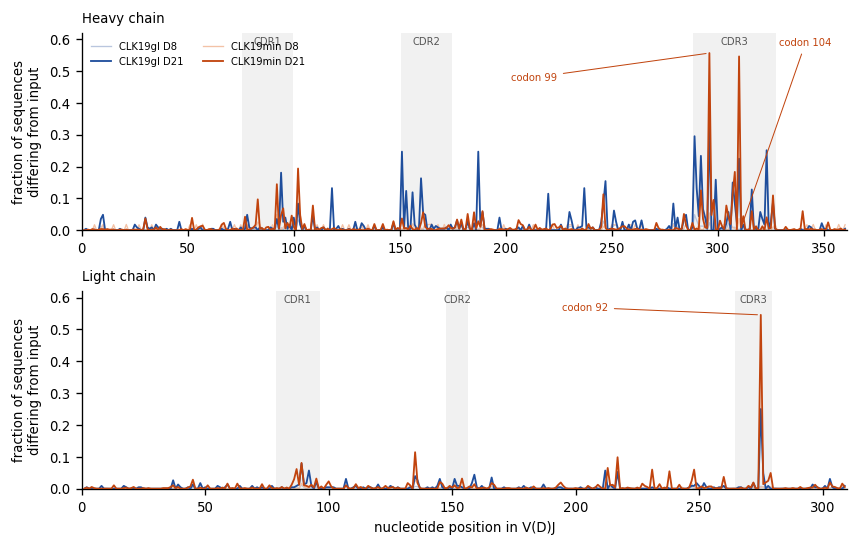

In [15]:
try:
    apply_figure_style()
except NameError:
    mpl.rcParams.update({"figure.dpi": 120, "font.size": 8, "axes.spines.top": False,
                         "axes.spines.right": False})

CDR = {"HC": {"CDR1": (76, 99), "CDR2": (151, 174), "CDR3": (289, 327)},
       "LC": {"CDR1": (79, 96), "CDR2": (148, 156), "CDR3": (265, 279)}}
colors = {("CLK19gl", "D8"): "#b9c6de", ("CLK19gl", "D21"): "#1f4e9c",
          ("CLK19min", "D8"): "#f3c2a6", ("CLK19min", "D21"): "#c1440e"}

fig, axes = plt.subplots(2, 1, figsize=(7.2, 4.6))
for ax, ch in zip(axes, ["HC", "LC"]):
    for (a, b) in CDR[ch].values():
        ax.axvspan(a - 0.5, b + 0.5, color="#000000", alpha=0.055, lw=0)
    for lab, (a, b) in CDR[ch].items():
        ax.text((a + b) / 2, 0.98, lab, ha="center", va="top", fontsize=6,
                color="#555555", transform=ax.get_xaxis_transform())
    for g in ["CLK19gl", "CLK19min"]:
        for d in ["D8", "D21"]:
            y = mutfreq[(g, ch, d)]
            ax.plot(np.arange(1, len(y) + 1), y, lw=1.1 if d == "D21" else 0.8,
                    color=colors[(g, d)], label=f"{g} {d}", zorder=3 if d == "D21" else 2)
    ax.set_ylabel("fraction of sequences\ndiffering from input")
    ax.set_xlim(0, len(mutfreq[("CLK19gl", ch, "D8")]) + 1)
    ax.set_ylim(0, 0.62)
    ax.set_title(f"{'Heavy' if ch == 'HC' else 'Light'} chain", loc="left", fontsize=8)
OFF = {("HC", 99): (-72, 0.47), ("HC", 104): (18, 0.58), ("LC", 92): (-62, 0.56)}
for ch, ax in zip(["HC", "LC"], axes):
    for codon in ([99, 104] if ch == "HC" else [92]):
        x = 3 * codon - 1
        dx, ty = OFF[(ch, codon)]
        ax.annotate(f"codon {codon}", xy=(x, mutfreq[("CLK19min", ch, "D21")][x - 1]),
                    xytext=(x + dx, ty), fontsize=6, color="#c1440e",
                    ha="right" if dx < 0 else "left",
                    arrowprops=dict(arrowstyle="-", lw=0.6, color="#c1440e"))
axes[0].legend(frameon=False, fontsize=6, loc="upper left", ncol=2)
axes[1].set_xlabel("nucleotide position in V(D)J")
fig.tight_layout()
fig.savefig("CLK19_repertoire_mutation_profile.png", dpi=300)

---
# Summary

1. CLK19min as supplied stops 9 nt short of a complete kappa domain; `GATATCAAA` (IGKJ3\*01,
   Asp-Ile-Lys) completes it for the germline derivation, and the repertoire data confirms those
   nucleotides are present in the transferred cells. They are **not** carried into the exported
   sequences: the AM input keeps the collaborators' 300 nt light-chain frame so that every codon maps
   1:1 onto a residue of the homology model, which was built from that shorter sequence (3.2).
2. The germline genes are IGHV1-2\*02 / IGHJ4 and IGKV1-33\*01 / IGKJ3\*01, with no somatic amino-acid
   substitutions anywhere in either V region.
3. CLK19gl assembled from germline segments reproduces the experimental sequence exactly outside the
   junction. The 27 heavy-chain and 3 light-chain junction nucleotides, which protein sequence cannot
   constrain, are now fixed from the D8 consensus.
4. The final CLK19min and CLK19gl nucleotide sequences differ at 66 (heavy) and 2 (light) positions
   and encode identical proteins. (Against the *inferred* CLK19gl of Part 1 the counts were 60 and 1;
   replacing the junction with the experimental nucleotides raised them, as cell 24 reports.)
5. At D21 the CLK19min repertoire consensus has moved at two CDR-H3 codons and one CDR-L3 codon; the
   germline repertoire consensus has not.
6. `CLK19max`, the collaborators' second recoding, is 105 (heavy) and 87 (light) nucleotides from
   CLK19gl and encodes the same protein pair. It is exported in the same frame but has no counterpart
   in the repertoire data, so Part 2 says nothing about it.

Exported by cell 24 to `CLK19_final_nt_sequences.fasta`: six sequences, heavy 360 nt / 120 aa and
light 300 nt / 100 aa, all translating to the two Fv chains of `CLK19gl_eOD-GT8_modeller.pdb`.
